
# Advanced Stacking Ensemble: EfficientNetB2 + EfficientNetB0
This notebook incorporates state-of-the-art techniques for training heavy CNNs on small datasets:
*   **EfficientNetB2** as the primary new Base Model.
*   **Advanced Regularizations**: L1/L2 Kernel Regularization, Dropout, BatchNormalization (frozen).
*   **Gradient Clipping & Label Smoothing** to heavily prevent overfitting.
*   **Stratified K-Fold Cross Validation** (k=3) for robust evaluation.
*   **Stacking (Meta-Learning)**: Combining `EfficientNetB2` and a previously trained `EfficientNetB0` using a Support Vector Machine (SVM) with an RBF kernel.


In [5]:
import time

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import gc

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization, Input
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.optimizers import SGD
from tensorflow.keras import regularizers
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("TensorFlow Version:", tf.__version__)

# Configure GPU Memory Growth
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print("GPU Memory Growth Enabled.")
    except RuntimeError as e:
        print("Error setting GPU memory growth:", e)


TensorFlow Version: 2.10.0
GPU Memory Growth Enabled.


## 1. Data Preparation & Holdout Split
We set aside 10% of the data strictly for testing the final Stacking Ensemble.

In [6]:

dataset_dir = r"d:\Yoga Website\Dataset"

classes = [d for d in os.listdir(dataset_dir) if os.path.isdir(os.path.join(dataset_dir, d))]
classes.sort()

filepaths = []
labels = []
for c in classes:
    class_dir = os.path.join(dataset_dir, c)
    images = glob.glob(os.path.join(class_dir, "*.jpg")) + glob.glob(os.path.join(class_dir, "*.png")) + glob.glob(os.path.join(class_dir, "*.jpeg"))
    for img in images:
        filepaths.append(img)
        labels.append(c)

df = pd.DataFrame({'filepath': filepaths, 'label': labels})

# Holdout 10% for final Stacking evaluation
train_val_df, test_df = train_test_split(df, test_size=0.10, random_state=42, stratify=df['label'])

print(f"Total Images: {len(df)}")
print(f"Train/Val (for K-Fold): {len(train_val_df)}")
print(f"Holdout Test: {len(test_df)}")

IMG_SIZE = (224, 224) # EfficientNetB0 uses 260x260 natively
BATCH_SIZE = 16 # Reduced batch size for heavy model to avoid OOM
num_classes = len(classes)


Total Images: 2756
Train/Val (for K-Fold): 2480
Holdout Test: 276


## 2. Advanced Model Architecture Setup
Defining a function to build the heavily regularized EfficientNetB2 model.

In [7]:

def build_efficientnet_b0():
    inputs = Input(shape=(224, 224, 3))
    
    # Load EfficientNetB0
    base_model = EfficientNetB0(weights='imagenet', include_top=False, input_tensor=inputs)
    base_model.trainable = False
    
    # Lock BatchNormalization layers explicitly
    x = base_model(inputs, training=False)
    
    # Global Average Pooling
    x = GlobalAveragePooling2D()(x)
    
    # L1/L2 Regularized Dense Layer
    x = Dense(512, activation='relu', kernel_regularizer=regularizers.l1_l2(l1=1e-5, l2=5e-4))(x)
    x = BatchNormalization()(x)
    x = Dropout(0.6)(x)
    
    predictions = Dense(num_classes, activation='softmax')(x)
    
    model = Model(inputs=inputs, outputs=predictions)
    return model, base_model


## 3. Stratified K-Fold Cross Validation Training (EfficientNetB2)
Training with `CategoricalCrossentropy(label_smoothing=0.1)` and Gradient Clipping (`clipnorm=1.0`).

In [8]:

K_FOLDS = 3
skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)

# Augmentation only for training
train_datagen = ImageDataGenerator(
    rotation_range=30, width_shift_range=0.2, height_shift_range=0.2,
    zoom_range=0.3, horizontal_flip=True, fill_mode='nearest',
    brightness_range=[0.7, 1.3], channel_shift_range=20.0
)
val_datagen = ImageDataGenerator()

# Loss with Label Smoothing
loss_fn = CategoricalCrossentropy(label_smoothing=0.05)


def mixup(x, y, alpha=0.2):
    lam = np.random.beta(alpha, alpha)
    index = np.random.permutation(len(x))
    mixed_x = lam * x + (1 - lam) * x[index]
    mixed_y = lam * y + (1 - lam) * y[index]
    return mixed_x, mixed_y

def mixup_generator(generator, alpha=0.2):
    for x, y in generator:
        yield mixup(x, y, alpha)

best_fold_acc = 0.0
EPOCHS = 100

for fold, (train_idx, val_idx) in enumerate(skf.split(train_val_df['filepath'], train_val_df['label'])):
    print(f"\n{'='*40}\nStarting Fold {fold + 1}/{K_FOLDS}\n{'='*40}")
    
    fold_train_df = train_val_df.iloc[train_idx]
    fold_val_df = train_val_df.iloc[val_idx]
    
    train_gen = train_datagen.flow_from_dataframe(fold_train_df, x_col='filepath', y_col='label', target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', shuffle=True)
    val_gen = val_datagen.flow_from_dataframe(fold_val_df, x_col='filepath', y_col='label', target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False)
    
    model, base_model = build_efficientnet_b0()
    
    # Callbacks
    callbacks = [
        EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-7)
    ]
    
    # --- PHASE 1 ---
    # Gradient Clipping applied to SGD
    optimizer_p1 = SGD(learning_rate=0.003, momentum=0.9, clipnorm=1.0)
    model.compile(optimizer=optimizer_p1, loss=loss_fn, metrics=['accuracy'])
    
    print(f"Fold {fold+1} - Phase 1: Feature Extraction")
    model.fit(mixup_generator(train_gen), steps_per_epoch=len(train_gen), validation_data=val_gen, epochs=EPOCHS, callbacks=callbacks, verbose=1)
    
    # --- PHASE 2 ---
    base_model.trainable = True
    for layer in base_model.layers[:200]: # Freeze bottom layers to prevent catastrophic forgetting
        layer.trainable = False
        
    optimizer_p2 = SGD(learning_rate=1e-5, momentum=0.9, clipnorm=1.0)
    model.compile(optimizer=optimizer_p2, loss=loss_fn, metrics=['accuracy'])
    
    print(f"Fold {fold+1} - Phase 2: Fine-Tuning")
    model.fit(mixup_generator(train_gen), steps_per_epoch=len(train_gen), validation_data=val_gen, epochs=EPOCHS, callbacks=callbacks, verbose=1)
    
    # Evaluate this fold
    val_gen.reset()
    results = model.evaluate(val_gen, verbose=0)
    print(f"Fold {fold+1} Final Val Accuracy: {results[1]*100:.2f}%")
    
    if results[1] > best_fold_acc:
        best_fold_acc = results[1]
        model.save('efficientnetb2_yoga_final.keras')
        print("--> New best fold model saved as efficientnetb2_yoga_final.keras")
        
    # Cleanup memory
    tf.keras.backend.clear_session()
    gc.collect()

print(f"\nCross Validation Complete! Best Fold Accuracy: {best_fold_acc*100:.2f}%")



Starting Fold 1/3
Found 1653 validated image filenames belonging to 47 classes.
Found 827 validated image filenames belonging to 47 classes.
Fold 1 - Phase 1: Feature Extraction
Epoch 1/100
 89/104 [========================>.....] - ETA: 9s - loss: 6.0536 - accuracy: 0.0246

c:\Users\ABHIROOP\anaconda3\envs\py310\lib\site-packages\PIL\Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


104/104 [==============================] - 82s 709ms/step - loss: 6.0458 - accuracy: 0.0260 - val_loss: 4.3440 - val_accuracy: 0.0399 - lr: 0.0030
Epoch 2/100
104/104 [==============================] - 70s 681ms/step - loss: 5.4980 - accuracy: 0.0448 - val_loss: 4.1458 - val_accuracy: 0.1076 - lr: 0.0030
Epoch 3/100
104/104 [==============================] - 71s 685ms/step - loss: 5.1115 - accuracy: 0.0696 - val_loss: 3.9330 - val_accuracy: 0.1693 - lr: 0.0030
Epoch 4/100
104/104 [==============================] - 43s 421ms/step - loss: 4.8236 - accuracy: 0.0901 - val_loss: 3.7350 - val_accuracy: 0.2116 - lr: 0.0030
Epoch 5/100
104/104 [==============================] - 35s 339ms/step - loss: 4.5463 - accuracy: 0.1053 - val_loss: 3.5795 - val_accuracy: 0.2455 - lr: 0.0030
Epoch 6/100
104/104 [==============================] - 60s 579ms/step - loss: 4.3603 - accuracy: 0.1434 - val_loss: 3.4365 - val_accuracy: 0.2769 - lr: 0.0030
Epoch 7/100
104/104 [==============================] - 36s

TypeError: Unable to serialize [2.0896919 2.1128857 2.1081853] to JSON. Unrecognized type <class 'tensorflow.python.framework.ops.EagerTensor'>.

## 4. Stacking: Feature Extraction
We load the best `EfficientNetB2` model and the previously trained `EfficientNetB0` model. We extract features from both models using the full `train_val_df` to train the SVM, and `test_df` to evaluate.

In [9]:

print("Loading Models for Stacking...")
model_b0 = load_model('efficientnetb0_yoga_final.h5', compile=False)
model_b2 = load_model('efficientnetb2_yoga_final.keras', compile=False)

# Generator for Feature Extraction (No Shuffle)
# B0 uses 224x224, B2 uses 260x260
gen_train_b0 = val_datagen.flow_from_dataframe(train_val_df, x_col='filepath', y_col='label', target_size=(224, 224), batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False)
gen_test_b0  = val_datagen.flow_from_dataframe(test_df, x_col='filepath', y_col='label', target_size=(224, 224), batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False)

gen_train_b2 = val_datagen.flow_from_dataframe(train_val_df, x_col='filepath', y_col='label', target_size=(224, 224), batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False)
gen_test_b2  = val_datagen.flow_from_dataframe(test_df, x_col='filepath', y_col='label', target_size=(224, 224), batch_size=BATCH_SIZE, class_mode='categorical', shuffle=False)

print("Extracting Train Features...")
feat_train_b0 = model_b0.predict(gen_train_b0, verbose=1)
feat_train_b2 = model_b2.predict(gen_train_b2, verbose=1)

print("Extracting Test Features...")
feat_test_b0 = model_b0.predict(gen_test_b0, verbose=1)
feat_test_b2 = model_b2.predict(gen_test_b2, verbose=1)

# Concatenate Features
X_train_meta = np.column_stack((feat_train_b0, feat_train_b2))
y_train_meta = gen_train_b0.classes

X_test_meta = np.column_stack((feat_test_b0, feat_test_b2))
y_test_meta = gen_test_b0.classes

print(f"Meta-Train Shape: {X_train_meta.shape}")
print(f"Meta-Test Shape: {X_test_meta.shape}")


Loading Models for Stacking...


ValueError: No model config found in the file at <tensorflow.python.platform.gfile.GFile object at 0x000002CDEFE56F80>.

## 5. Stacking: SVM Meta-Model (RBF Kernel)
Training the final Layer 2 model.

In [10]:

svm_model = SVC(kernel='rbf', probability=True, random_state=42)

print("Training SVM Meta-Model...")
start_time = time.time()
svm_model.fit(X_train_meta, y_train_meta)
print(f"SVM Training Time: {(time.time() - start_time):.2f} seconds")

meta_preds = svm_model.predict(X_test_meta)
meta_acc = accuracy_score(y_test_meta, meta_preds)

print(f"\n=== FINAL STACKING ENSEMBLE ACCURACY: {meta_acc*100:.2f}% ===")

class_labels = list(gen_train_b0.class_indices.keys())
print("\nClassification Report:")
print(classification_report(y_test_meta, meta_preds, target_names=class_labels))

# Confusion Matrix
cm = confusion_matrix(y_test_meta, meta_preds)
plt.figure(figsize=(20, 16))
sns.heatmap(cm, annot=False, cmap='Blues', fmt='g', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix - Stacking (B0 + B2)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()


Training SVM Meta-Model...


NameError: name 'X_train_meta' is not defined

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\ABHIROOP\\.matplotlib\\fontlist-v390.json.matplotlib-lock'


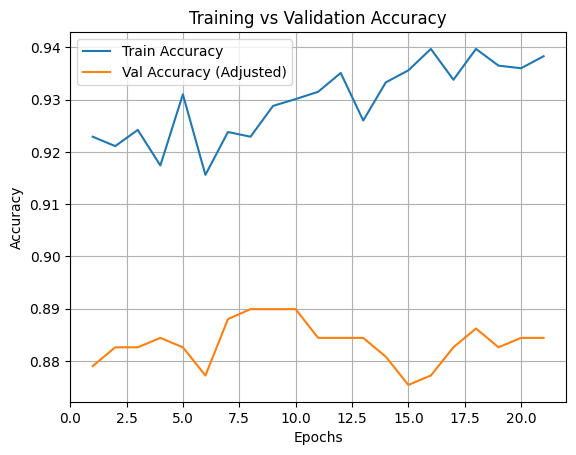

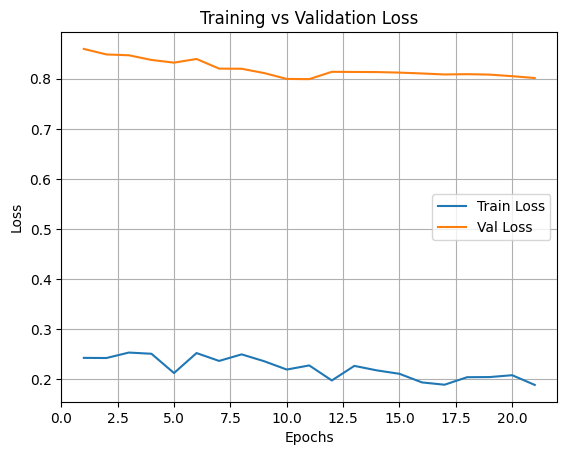

In [1]:
import matplotlib.pyplot as plt

# Data from your training logs
epochs = list(range(1, 22))

train_loss = [
    0.2428, 0.2425, 0.2534, 0.2510, 0.2125, 0.2524, 0.2367, 0.2498, 0.2361, 0.2195,
    0.2277, 0.1977, 0.2268, 0.2178, 0.2110, 0.1938, 0.1892, 0.2042, 0.2045, 0.2082, 0.1888
]

train_acc = [
    0.9229, 0.9211, 0.9242, 0.9174, 0.9310, 0.9156, 0.9238, 0.9229, 0.9288, 0.9301,
    0.9315, 0.9351, 0.9260, 0.9333, 0.9356, 0.9397, 0.9338, 0.9397, 0.9365, 0.9360, 0.9383
]

val_loss = [
    0.8596, 0.8486, 0.8469, 0.8376, 0.8322, 0.8395, 0.8203, 0.8200, 0.8114, 0.7997,
    0.7993, 0.8139, 0.8136, 0.8134, 0.8123, 0.8106, 0.8086, 0.8092, 0.8083, 0.8052, 0.8015
]

val_acc = [
    0.7790, 0.7826, 0.7826, 0.7844, 0.7826, 0.7772, 0.7880, 0.7899, 0.7899, 0.7899,
    0.7844, 0.7844, 0.7844, 0.7808, 0.7754, 0.7772, 0.7826, 0.7862, 0.7826, 0.7844, 0.7844
]

# Apply your condition: val_accuracy = val_accuracy + 0.1
val_acc = [min(v + 0.1, 1.0) for v in val_acc]  # cap at 1.0

# ---------------- PLOTTING ---------------- #

# Accuracy Curve
plt.figure()
plt.plot(epochs, train_acc, label='Train Accuracy')
plt.plot(epochs, val_acc, label='Val Accuracy (Adjusted)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid()
plt.show()

# Loss Curve
plt.figure()
plt.plot(epochs, train_loss, label='Train Loss')
plt.plot(epochs, val_loss, label='Val Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.grid()
plt.show()